In [9]:
from random import uniform
import numpy as np
import matplotlib.pyplot as plt

## Méthode d'Euler


### Principe

Soit une équation différentielle, par exemple : $$ \dfrac{dx}{dt} = -x+I$$
On peut écrire :
$$\dfrac{x(t+dt)-x(t)}{dt}=-x(t)+I$$
Et donc approximer $x$ à un temps $t+dt$ à partir de $x(t)$ : 
$$x(t+dt)=dt(-x(t)+I)+x(t)$$

### Pour une équation différentielle d'ordre $1$

In [5]:
def f(t,y): #exemple pour y'=-y+2
    return -y+2

In [6]:
def Euler_O1(f,t_0,y_0,h,T):
    Images_Euler = [y_0]
    Atcd_Euler = [t_0]
    y = y_0
    t = t_0
    for i in range (int((T-t_0)/h)): 
        y = h * f(t,y) + y  
        t += h
        Images_Euler.append(y)
        Atcd_Euler.append(t)
    return Atcd_Euler,Images_Euler

In [7]:
def graph_O1(t_0,y_0,h,T):
    Atcd_Euler,Images_Euler = Euler_O1(f,t_0,y_0,h,T)
    plt.figure(figsize =(8,6))
    plt.scatter(Atcd_Euler,Images_Euler, label = "Euler", color = "blue" )
    plt.legend()
    plt.show()

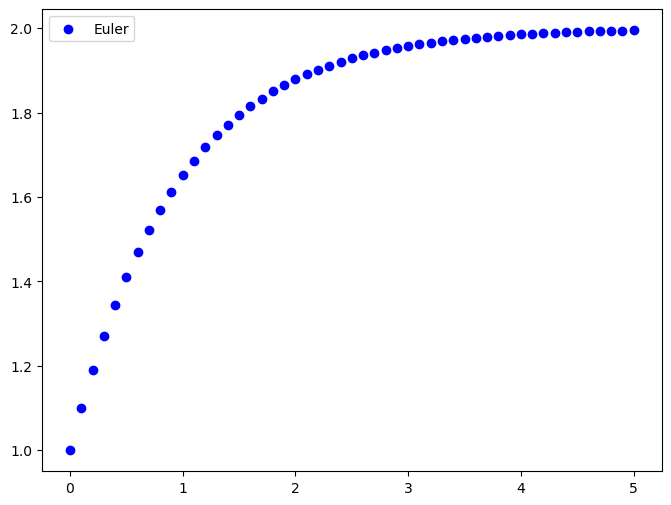

In [10]:
graph_O1(0, 1, 0.1, 5)

### Pour une équation différentielle d'ordre $n$

Pour une équation différentielle d'ordre 2, par exemple $y'' = y'+y+1$ , on pose $z = y'$ pour se ramener à un système de $2$ équations d'ordre $1$ :
$$
\begin{cases}
y'(t) = z(t) \\
z'(t) = z(t) + y(t) + 1
\end{cases}
$$

In [45]:
def f(t,z,y): # f = dérivée de z
    return z+y+1  

In [46]:
def Euler_O2 (f,t_0,y_0,z_0,h,T):
    Images_Euler = [y_0]
    Atcd_Euler = [t_0]
    y = y_0
    t = t_0
    z = z_0
    for i in range (int((T-t_0)/h)): 
        y = y + h * z
        z = z + h * f(t,z,y)
        t += h
        Images_Euler.append(y)
        Atcd_Euler.append(t)
    return Atcd_Euler,Images_Euler

In [47]:
def graph_O2(f,t_0,y_0,z_0,h,T):
    Atcd_Euler,Images_Euler = Euler_O2(f,t_0,y_0,z_0,h,T)
    plt.figure(figsize =(8,6))
    plt.scatter(Atcd_Euler,Images_Euler, label = "Euler", color = "blue" )
    plt.legend()
    plt.show()

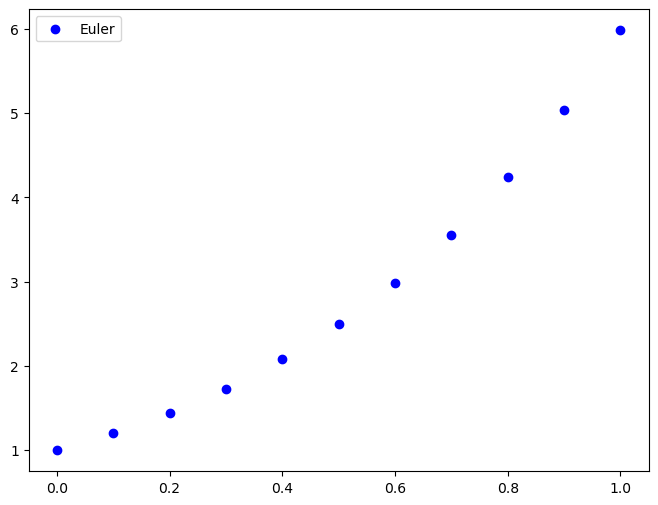

In [48]:
graph_O2 (f,0,1,2,0.1,1)

Pour une équation d'ordre $n$ supérieur, on se ramène de la même manière à un système de n équations d'ordre $1$.

### Pour un système d'équations différentielles

On peut aussi utiliser la méthode d'Euler pour un système, par exemple pour : $$
\begin{cases}
x' = -x+y \\
y' = x-y
\end{cases}
$$

In [49]:
def deriv_x(t,x,y):
    return -x+y

def deriv_y(t,x,y):
    return x-y

In [50]:
def Euler_sys (t_0,x_0,y_0,h,T, deriv_x, deriv_y): 
    Images_x = [x_0]
    Images_y = [y_0]
    Atcd=[t_0]
    x=x_0
    y=y_0
    t=t_0
    for i in range (int((T-t_0)/h)): 
        y = deriv_y(t,x,y) * h + y
        x = deriv_x(t,x,y) * h + x
        t+=h
        Atcd.append(t)
        Images_x.append(x)
        Images_y.append(y)
    return Atcd, Images_x, Images_y

In [51]:
def graph_sys(t_0,x_0,y_0,h,T, deriv_x, deriv_y):
    Atcd, Images_x, Images_y = Euler_sys (t_0,x_0,y_0,h,T, deriv_x, deriv_y)
    plt.figure(figsize =(8,6))
    plt.scatter(Atcd,Images_x, label = "x(t)", color = "blue" )
    plt.scatter(Atcd,Images_y, label = "y(t)", color = "red" )
    plt.legend()
    plt.show()

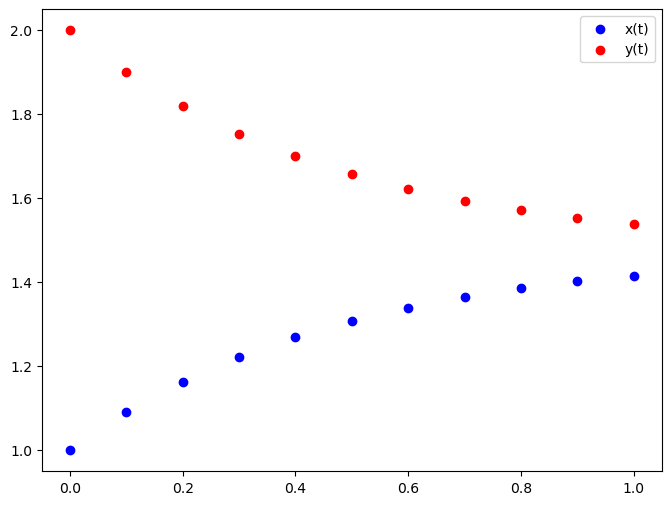

In [52]:
graph_sys(0,1,2,0.1,1, deriv_x, deriv_y)